<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/chest_xray_pneumonia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
pip install kagglehub opencv-python numpy tensorflow scikit-learn seaborn matplotlib

--- Mengunduh Dataset dari Kaggle ---
Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia
Menggunakan sampel citra untuk Modul 1-3: /kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/NORMAL2-IM-0771-0001.jpeg



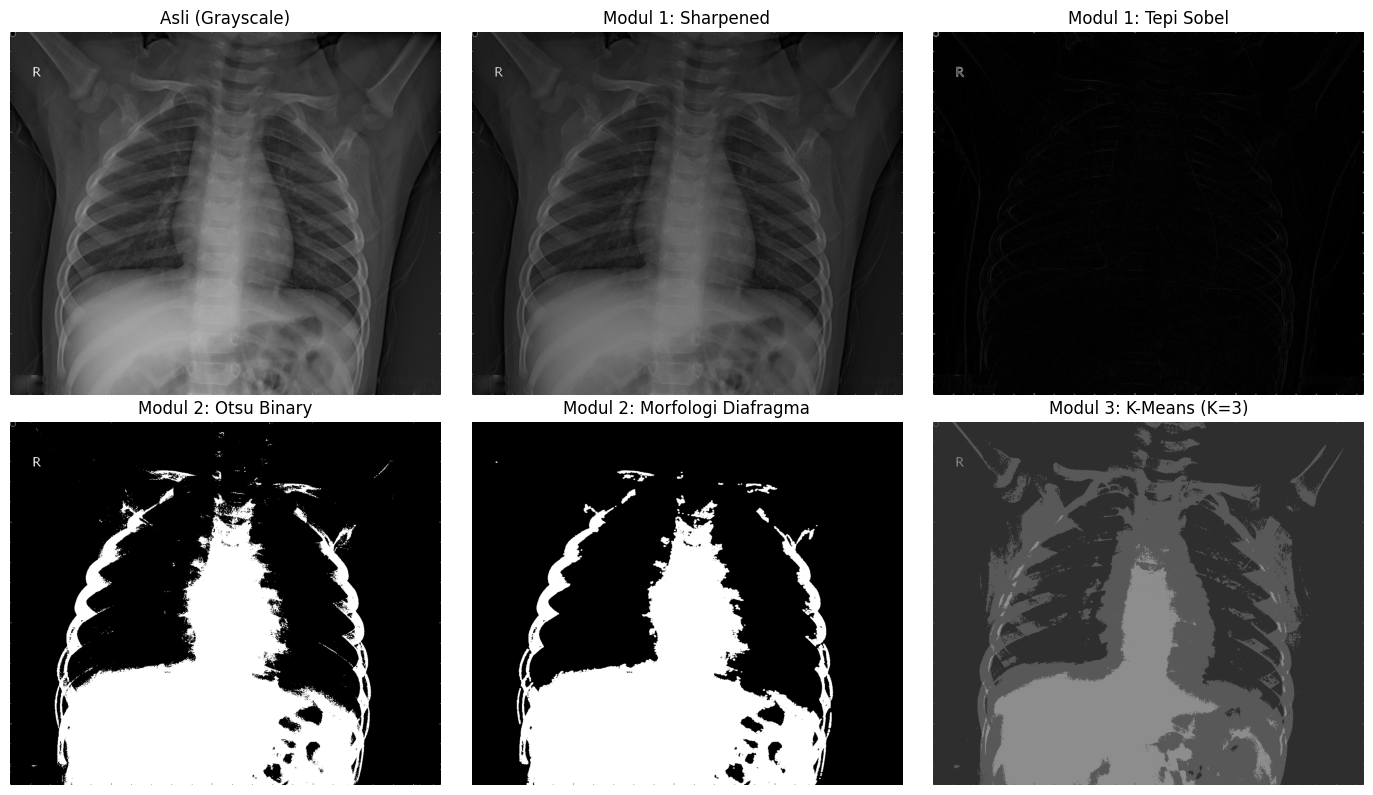


--- Modul 4: Menyiapkan Data Generator ---
Found 5216 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

--- Melatih Model CNN ---
Epoch 1/3
163/163 ━━━━━━━━━━━━━━━━━━━━ 212s 1s/step - accuracy: 0.7705 - loss: 0.4377 - val_accuracy: 0.7692 - val_loss: 0.6436
Epoch 2/3
163/163 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.8898 - loss: 0.2744 - val_accuracy: 0.7933 - val_loss: 0.4580
Epoch 3/3
163/163 ━━━━━━━━━━━━━━━━━━━━ 173s 1s/step - accuracy: 0.9038 - loss: 0.2449 - val_accuracy: 0.7724 - val_loss: 0.5843
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 430ms/step

================ CLASSIFICATION REPORT ================
              precision    recall  f1-score   support

      NORMAL       0.93      0.43      0.58       234
   PNEUMONIA       0.74      0.98      0.84       390

    accuracy                           0.77       624
   macro avg       0.83      0.70      0.71       624
weighted avg       0.81      0.77      0.75       624



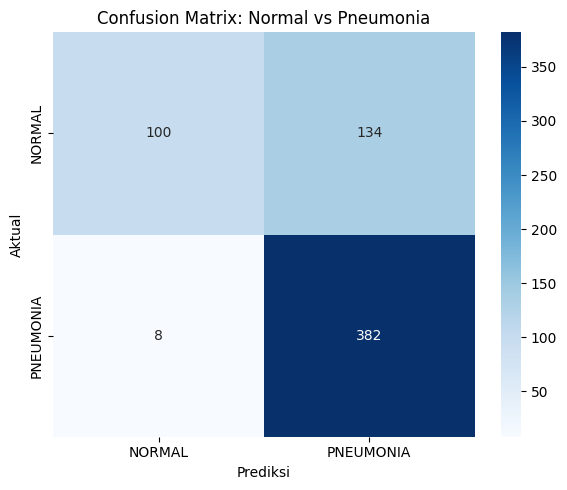

In [7]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
import kagglehub

# =====================================================================
# 0. UNDUH DATASET MENGGUNAKAN KAGGLEHUB
# =====================================================================
print("--- Mengunduh Dataset dari Kaggle ---")
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Path to dataset files:", path)

# Lokasi folder train, val, dan test dari struktur dataset Kaggle
dataset_base = os.path.join(path, "chest_xray")
train_dir = os.path.join(dataset_base, "train")
val_dir = os.path.join(dataset_base, "val")
test_dir = os.path.join(dataset_base, "test")

# Ambil 1 contoh sampel citra dari folder train untuk demonstrasi Modul 1-3
sample_images = glob.glob(os.path.join(train_dir, "NORMAL", "*.jpeg"))
if not sample_images:
    sample_images = glob.glob(os.path.join(train_dir, "PNEUMONIA", "*.jpeg"))

sample_img_path = sample_images[0]
print(f"Menggunakan sampel citra untuk Modul 1-3: {sample_img_path}\n")


# =====================================================================
# MODUL 1: High-Pass Filtering & Ekstraksi Sobel
# =====================================================================
def modul_1_processing(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    # 1. Frekuensi rendah dengan Gaussian Blur
    blurred = cv2.GaussianBlur(img, (15, 15), 0)

    # 2. Ekstrak frekuensi tinggi menggunakan cv2.subtract
    high_freq = cv2.subtract(img, blurred)

    # 3. Gabungkan citra asli (bobot 0.7) dengan detail frekuensi tinggi
    sharpened = cv2.addWeighted(img, 0.7, high_freq, 0.3, 0)

    # 4. Gradien tepi organ paru dengan kernel Sobel ukuran 3
    sobel_x = cv2.Sobel(sharpened, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(sharpened, cv2.CV_64F, 0, 1, ksize=3)

    sobel_grad = cv2.magnitude(sobel_x, sobel_y)
    sobel_grad = cv2.normalize(sobel_grad, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    return img, sharpened, sobel_grad


# =====================================================================
# MODUL 2: Binerisasi Otsu & Morfologi Tepi Diafragma
# =====================================================================
def modul_2_processing(sharpened_img):
    # 1. Binerisasi Otsu otomatis
    _, otsu_thresh = cv2.threshold(sharpened_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 2. Kernel morfologi
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

    # 3. Sekuens Erosi dilanjutkan Dilasi (1 iterasi)
    eroded = cv2.erode(otsu_thresh, kernel, iterations=1)
    smooth_mask = cv2.dilate(eroded, kernel, iterations=1)

    return otsu_thresh, smooth_mask


# =====================================================================
# MODUL 3: Klasterisasi K-Means K=3 (Maksimal 20 Iterasi)
# =====================================================================
def modul_3_processing(image_path):
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 1. Ubah dimensi menjadi 3 kolom (Height*Width, 3)
    pixel_values = img_rgb.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # 2. Kriteria berhenti: Maksimal 20 iterasi (MAX_ITER=20)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
    k = 3  # Udara (Hitam), Jaringan/Cairan (Abu-abu), Tulang (Putih)

    # 3. Eksekusi K-Means
    _, labels, centers = cv2.kmeans(
        pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS
    )

    centers = np.uint8(centers)
    segmented_pixels = centers[labels.flatten()]
    segmented_image = segmented_pixels.reshape(img_rgb.shape)

    return segmented_image


# =====================================================================
# MODUL 4: Training CNN & Evaluasi (Normal vs Pneumonia)
# =====================================================================
def modul_4_train_and_eval(train_path, test_path, img_size=(150, 150), batch_size=32, epochs=5):
    print("\n--- Modul 4: Menyiapkan Data Generator ---")

    # 1. Augmentasi data train (Rotasi dan Zoom/Perbesaran)
    train_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=15,
        zoom_range=0.15,
        horizontal_flip=True
    )

    # Generator data uji/evaluasi
    test_datagen = ImageDataGenerator(rescale=1./255)

    train_generator = train_datagen.flow_from_directory(
        train_path,
        target_size=img_size,
        batch_size=batch_size,
        class_mode='binary',
        shuffle=True
    )

    # Menggunakan folder 'test' untuk evaluasi akhir karena sampel lebih seimbang
    test_generator = test_datagen.flow_from_directory(
        test_path,
        target_size=img_size,
        batch_size=batch_size,
        class_mode='binary',
        shuffle=False
    )

    # 2. Arsitektur CNN Sederhana
    model = models.Sequential([
        layers.Input(shape=(img_size[0], img_size[1], 3)),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    print("\n--- Melatih Model CNN ---")
    model.fit(
        train_generator,
        epochs=epochs,
        validation_data=test_generator
    )

    # 3. Evaluasi Prediksi
    test_generator.reset()
    y_pred_probs = model.predict(test_generator)
    y_pred = (y_pred_probs > 0.5).astype(int).flatten()
    y_true = test_generator.classes
    class_names = list(test_generator.class_indices.keys())

    # 4. Cetak Classification Report
    print("\n================ CLASSIFICATION REPORT ================")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # 5. Bagan Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix: Normal vs Pneumonia')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.tight_layout()
    plt.show()


# =====================================================================
# EKSEKUSI SELURUH MODUL
# =====================================================================
if __name__ == "__main__":
    # Run Modul 1
    orig, sharpened, sobel_edges = modul_1_processing(sample_img_path)

    # Run Modul 2
    otsu_thresh, smooth_diafragma = modul_2_processing(sharpened)

    # Run Modul 3
    segmented_kmeans = modul_3_processing(sample_img_path)

    # Visualisasi Hasil Modul 1, 2, dan 3
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(orig, cmap='gray')
    axes[0, 0].set_title('Asli (Grayscale)')

    axes[0, 1].imshow(sharpened, cmap='gray')
    axes[0, 1].set_title('Modul 1: Sharpened')

    axes[0, 2].imshow(sobel_edges, cmap='gray')
    axes[0, 2].set_title('Modul 1: Tepi Sobel')

    axes[1, 0].imshow(otsu_thresh, cmap='gray')
    axes[1, 0].set_title('Modul 2: Otsu Binary')

    axes[1, 1].imshow(smooth_diafragma, cmap='gray')
    axes[1, 1].set_title('Modul 2: Morfologi Diafragma')

    axes[1, 2].imshow(segmented_kmeans)
    axes[1, 2].set_title('Modul 3: K-Means (K=3)')

    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Run Modul 4 (Training & Evaluasi Model)
    modul_4_train_and_eval(train_dir, test_dir, epochs=3)